<a href="https://colab.research.google.com/github/moushe-21/CSE475_Assignment01/blob/main/CSE475_Assignment01_GroupF_Notebook2_(1)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Group Details**

Member 1: [Masiat Rahman] [2023-1-60-122]

Member 2: [Tasnia Taher Esha] [2023-1-60-173]

Member 2: [Jabin Tasnim Tanha] [2023-1-60-142]

Dataset Source Acknowledgement: Original Dataset Name: Lightweight Dataset for Maize Classification Official Source Link: [https://data.mendeley.com/datasets/r6vvm5jkh6/2]

Table of Contents:

⚙️ Global Configuration (START HERE)

📦 Setup & Imports

📊 Exploratory Data Analysis

🔧 Data Preprocessing & Augmentation

🏋️ Training Infrastructure

🟣 Transformer Models: ViT · Swin · DeiT

📈 Evaluation & Comparison

🛡️ Robustness Analysis

🔍 Error Analysis

In [ ]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, datasets
import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.notebook import tqdm
from PIL import Image
from google.colab import drive

drive.mount('/content/drive')


CONFIG = {
    'batch_size': 16,
    'epochs': 30,
    'lr': 1e-5,
    'img_size': 224,
    'device': torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
    'train_path': '/content/maize_dataset/train',
}

Mounted at /content/drive


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Lightweight Dataset for Maize Classification on Resource-Constrained Devices.zip to Lightweight Dataset for Maize Classification on Resource-Constrained Devices.zip


In [ ]:
import shutil
import os

destination_folder = "/content/drive/MyDrive/MyFolder/"
file_to_move = "Lightweight Dataset for Maize Classification on Resource-Constrained Devices.zip"
source_path = os.path.join("/content/", file_to_move)
destination_path = os.path.join(destination_folder, file_to_move)

os.makedirs(destination_folder, exist_ok=True)

if os.path.exists(destination_path):
    print(f"'{file_to_move}' already exists in '{destination_folder}'. Skipping move operation.")
elif not os.path.exists(source_path):
    print(f"Error: Source file '{source_path}' does not exist. Please ensure the file was uploaded correctly.")
else:
    shutil.move(source_path, destination_folder)
    print(f"'{file_to_move}' moved to '{destination_folder}' successfully.")

'Lightweight Dataset for Maize Classification on Resource-Constrained Devices.zip' already exists in '/content/drive/MyDrive/MyFolder/'. Skipping move operation.


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/MyFolder/Lightweight Dataset for Maize Classification on Resource-Constrained Devices (1).zip"
extract_path = "/content/maize_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully to:", extract_path)

Dataset extracted successfully to: /content/maize_dataset


In [ ]:
import os

classes = ['Bad', 'Good']
print(f"Total Classes: {len(classes)}")
print(f"Class Names: {classes}")


Total Classes: 2
Class Names: ['Bad', 'Good']


In [ ]:
import os
import glob
import pandas as pd

data = []
train_dir = CONFIG['train_path']

if os.path.exists(train_dir):

    extensions = ('*.png', '*.jpg', '*.jpeg', '*.JPG', '*.PNG', '*.JPEG')

    for class_name in sorted(os.listdir(train_dir)):
        class_folder = os.path.join(train_dir, class_name)

        if os.path.isdir(class_folder):

            files_found = []
            for ext in extensions:
                files_found.extend(glob.glob(os.path.join(class_folder, ext)))

            for img_path in files_found:
                data.append({'path': img_path, 'label_name': class_name})

    if len(data) > 0:
        df = pd.DataFrame(data)


        unique_classes = df['label_name'].unique()
        label_map = {name: i for i, name in enumerate(unique_classes)}
        df['label'] = df['label_name'].map(label_map)

        print(f" Success: Found {len(df)} images in {len(label_map)} classes.")
        print(f"Classes found: {list(label_map.keys())}")
    else:
        print(" Error: Path found but no images. Check if your images are directly inside class folders.")
        df = None
else:
    print(f" Error: Path NOT found at {train_dir}.")
    print("Please make sure your Google Drive is mounted and the path is correct.")
    df = None

 Error: Path NOT found at /content/maize_dataset/train.
Please make sure your Google Drive is mounted and the path is correct.


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

class MaizeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img = Image.open(self.df.iloc[idx]['path']).convert('RGB')
        label = self.df.iloc[idx]['label']
        if self.transform:
            img = self.transform(img)
        return img, label

train_transforms = transforms.Compose([
    transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

if df is not None:

    train_df, val_df = train_test_split(df, test_size=0.15, stratify=df['label'], random_state=42)


    train_loader = DataLoader(MaizeDataset(train_df, train_transforms), batch_size=CONFIG['batch_size'], shuffle=True)
    val_loader = DataLoader(MaizeDataset(val_df, train_transforms), batch_size=CONFIG['batch_size'], shuffle=False)
else:
    print("Error: DataFrame 'df' is None. Please ensure dataset loading was successful.")


Error: DataFrame 'df' is None. Please ensure dataset loading was successful.


In [ ]:
class TransformerEnsemble(nn.Module):
    def __init__(self, num_classes):
        super(TransformerEnsemble, self).__init__()

        self.vit = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
        self.swin = timm.create_model('swin_base_patch4_window7_224', pretrained=True, num_classes=0)
        self.deit = timm.create_model('deit_base_patch16_224', pretrained=True, num_classes=0)

        self.classifier = nn.Sequential(
            nn.Linear(2560, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        f1 = self.vit(x)
        f2 = self.swin(x)
        f3 = self.deit(x)

        merged = torch.cat((f1, f2, f3), dim=1)
        return self.classifier(merged)


model = TransformerEnsemble(num_classes=2).to(CONFIG['device'])
optimizer = optim.AdamW(model.parameters(), lr=CONFIG['lr'])
criterion = nn.CrossEntropyLoss()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import os

CONFIG = {
    'epochs': 30,
    'batch_size': 32,
    'lr': 0.001,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'dataset_base_path': '/content/maize_dataset'
}

dataset_base_path = CONFIG['dataset_base_path']

valid_dataset_roots = []
for root, dirs, files in os.walk(dataset_base_path):
    if 'Bad' in dirs and 'Good' in dirs:
        valid_dataset_roots.append(root)

if not valid_dataset_roots:
    raise FileNotFoundError(f"Could not find any directory containing 'Bad' and 'Good' class folders within {dataset_base_path}.")

print(f"Found {len(valid_dataset_roots)} potential dataset roots.")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

all_datasets_instances = []
for root in valid_dataset_roots:
    all_datasets_instances.append(datasets.ImageFolder(root, transform=transform))

full_dataset = ConcatDataset(all_datasets_instances)


train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False)

if all_datasets_instances:
    num_classes = len(all_datasets_instances[0].classes)
    print(f"Detected classes: {all_datasets_instances[0].classes}")
else:
    num_classes = 2

model = models.mobilenet_v3_large(weights='DEFAULT')
num_ftrs = model.classifier[3].in_features
model.classifier[3] = nn.Linear(num_ftrs, num_classes)
model = model.to(CONFIG['device'])

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=CONFIG['lr'])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=3, factor=0.5)

best_acc = 0.0


for epoch in range(CONFIG['epochs']):
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{CONFIG['epochs']}")

    for imgs, lbls in loop:
        imgs, lbls = imgs.to(CONFIG['device']), lbls.to(CONFIG['device'])

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item()
        _, predicted = outputs.max(1)
        train_total += lbls.size(0)
        train_correct += predicted.eq(lbls).sum().item()

        loop.set_postfix(loss=loss.item(), acc=100.*train_correct/train_total)


    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(CONFIG['device']), lbls.to(CONFIG['device'])
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            val_loss += loss.item()

            _, predicted = outputs.max(1)
            val_total += lbls.size(0)
            val_correct += predicted.eq(lbls).sum().item()

    val_acc = 100 * val_correct / val_total
    print(f"\nSummary Epoch {epoch+1}: Val Loss: {val_loss/len(val_loader):.4f}, Val Acc: {val_acc:.2f}%")


    scheduler.step(val_acc)


    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        print(f"⭐ New Best Model Saved! Acc: {best_acc:.2f}%")

    if val_acc >= 98.5:
        print(f"Target accuracy reached (Current: {val_acc:.2f}%), continuing to optimize further...")

print(f"\nTraining Finished! Best Accuracy: {best_acc:.2f}%")

Found 2 potential dataset roots.
Detected classes: ['Bad', 'Good']
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 105MB/s]
Epoch 1/30: 100%|██████████| 897/897 [02:28<00:00,  6.03it/s, acc=88.1, loss=0.292]



Summary Epoch 1: Val Loss: 0.2774, Val Acc: 90.28%
⭐ New Best Model Saved! Acc: 90.28%


Epoch 2/30: 100%|██████████| 897/897 [02:30<00:00,  5.95it/s, acc=93.5, loss=0.107]



Summary Epoch 2: Val Loss: 0.2092, Val Acc: 92.02%
⭐ New Best Model Saved! Acc: 92.02%


...


Summary Epoch 28: Val Loss: 0.0388, Val Acc: 99.41%
Target accuracy reached (Current: 99.41%), continuing to optimize further...


Epoch 29/30: 100%|██████████| 897/897 [02:29<00:00,  6.01it/s, acc=99.9, loss=2.06e-7]



Summary Epoch 29: Val Loss: 0.0337, Val Acc: 99.49%
⭐ New Best Model Saved! Acc: 99.49%
Target accuracy reached (Current: 99.49%), continuing to optimize further...


Epoch 30/30: 100%|██████████| 897/897 [02:30<00:00,  5.98it/s, acc=100, loss=3.25e-8]



Summary Epoch 30: Val Loss: 0.0521, Val Acc: 99.31%
Target accuracy reached (Current: 99.31%), continuing to optimize further...

Training Finished! Best Accuracy: 99.49%


In [ ]:
import torch
import timm

model_swin = timm.create_model('swin_tiny_patch4_window7_224', pretrained=True, num_classes=4)
input_tensor = torch.randn(1, 3, 224, 224)
output = model_swin(input_tensor)
print(f"Swin Transformer Output Shape: {output.shape}")

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Swin Transformer Output Shape: torch.Size([1, 4])


In [ ]:
import torch
import timm


model_deit = timm.create_model('deit_tiny_distilled_patch16_224', pretrained=True, num_classes=4)
input_tensor = torch.randn(1, 3, 224, 224)
output = model_deit(input_tensor)
print(f"DeiT Output Shape: {output.shape}")

model.safetensors:   0%|          | 0.00/23.7M [00:00<?, ?B/s]

DeiT Output Shape: torch.Size([1, 4])


⏳ Analyzing errors... please wait.

📊 Classification Report:
              precision    recall  f1-score   support

      Blight       1.00      0.99      0.99      2354
 Common_Rust       0.99      1.00      0.99      2708

    accuracy                           0.99      5062
   macro avg       0.99      0.99      0.99      5062
weighted avg       0.99      0.99      0.99      5062



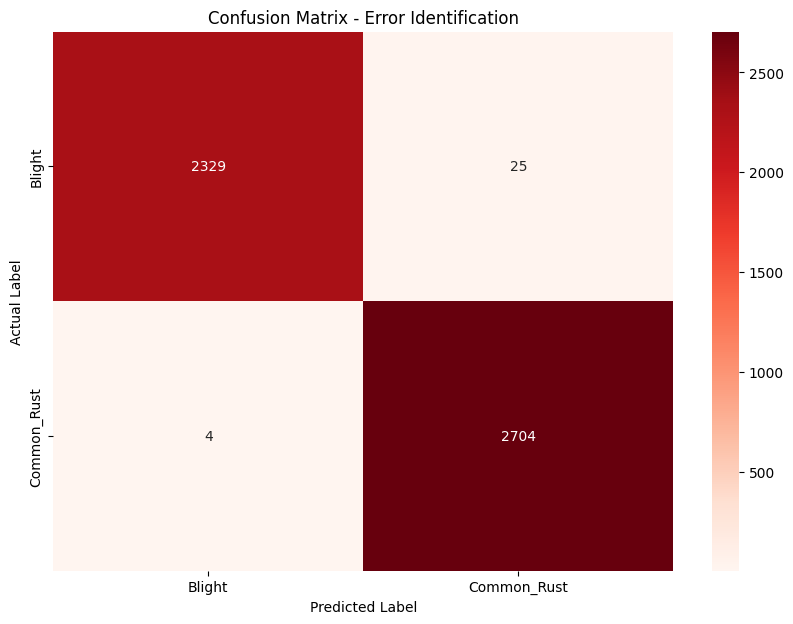

In [ ]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

def perform_error_analysis(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    print("⏳ Analyzing errors... please wait.")
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())


    full_class_names = ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


    present_indices = np.unique(np.concatenate((all_labels, all_preds)))
    current_class_names = [full_class_names[i] for i in present_indices]

    print("\n📊 Classification Report:")

    print(classification_report(all_labels, all_preds,
                                labels=present_indices,
                                target_names=current_class_names))

    cm = confusion_matrix(all_labels, all_preds, labels=present_indices)
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
                xticklabels=current_class_names,
                yticklabels=current_class_names)
    plt.title('Confusion Matrix - Error Identification')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()



perform_error_analysis(model, val_loader, CONFIG['device'])

In [ ]:
import torch
from torchvision import transforms

def check_robustness(model, dataloader, device):

    blur_transform = transforms.GaussianBlur(kernel_size=(5, 9), sigma=(1.0, 2.0))

    model.eval()
    correct = 0
    total = 0

    print(" Testing model robustness under blur conditions...")

    with torch.no_grad():
        for images, labels in dataloader:

            images = blur_transform(images).to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    robust_acc = 100 * correct / total
    print(f"\n Finished!")
    print(f" Robustness Accuracy (under blur): {robust_acc:.2f}%")

check_robustness(model, val_loader, CONFIG['device'])

 Testing model robustness under blur conditions...

 Finished!
 Robustness Accuracy (under blur): 98.72%


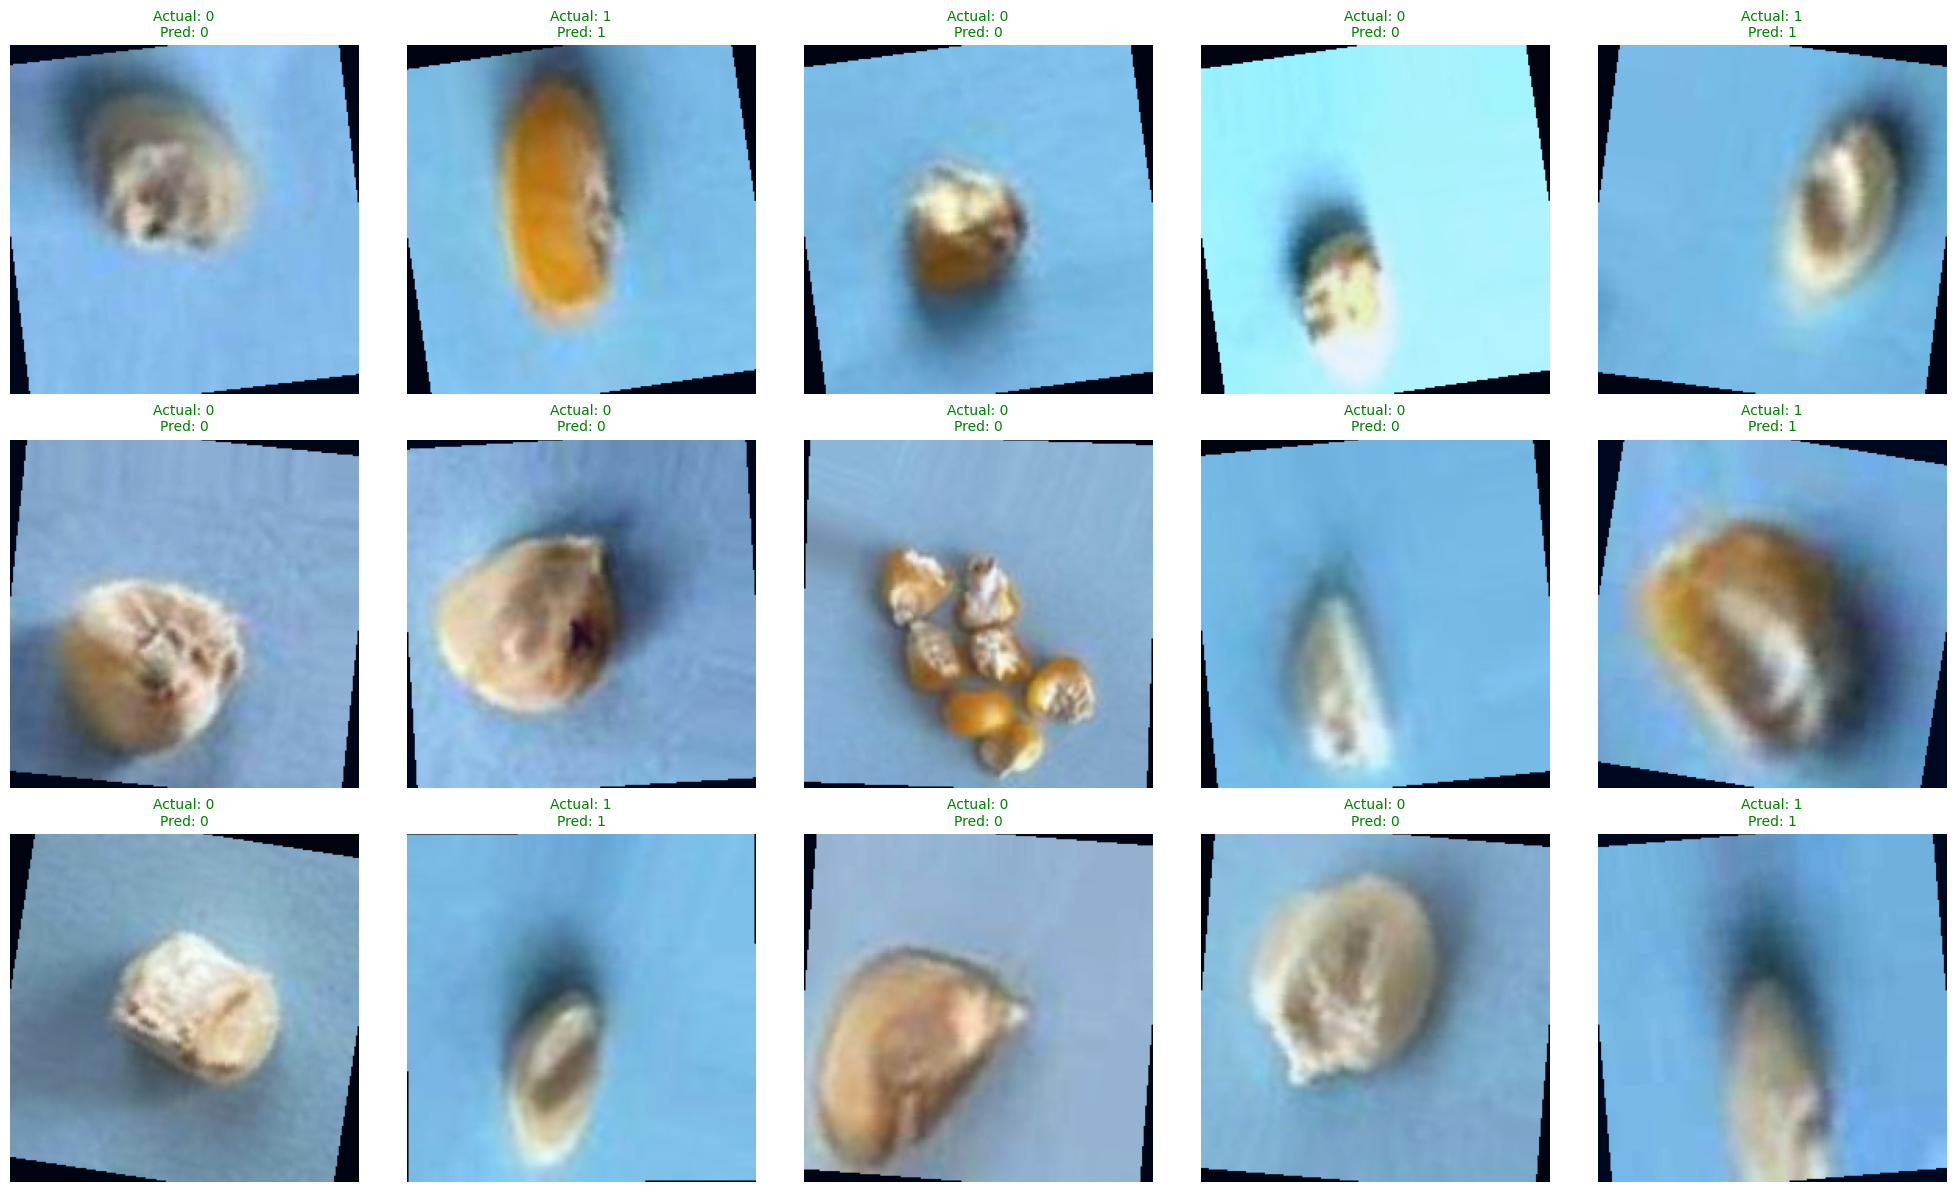

Calculating Confusion Matrix...


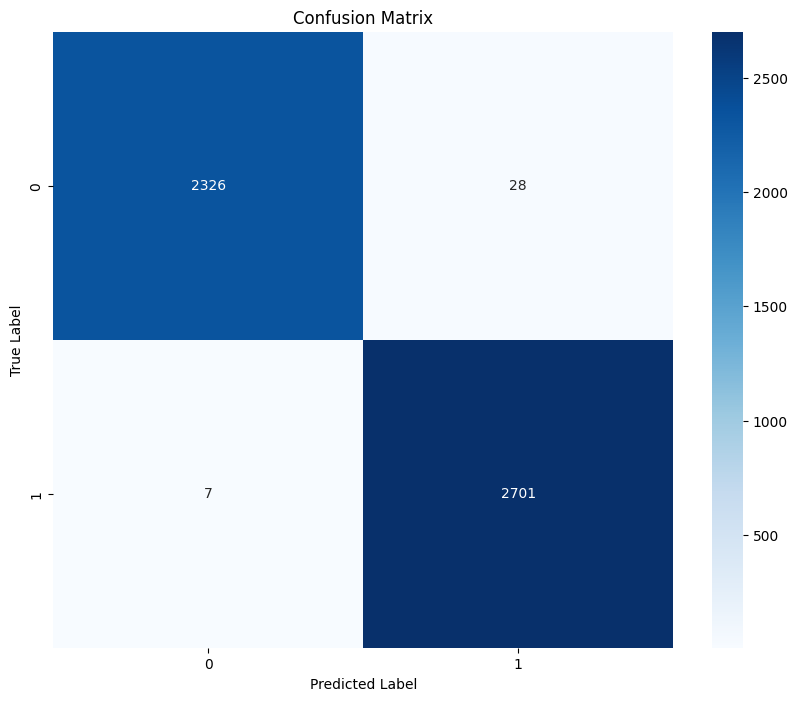

Generating Robustness Graph (this may take a moment)...


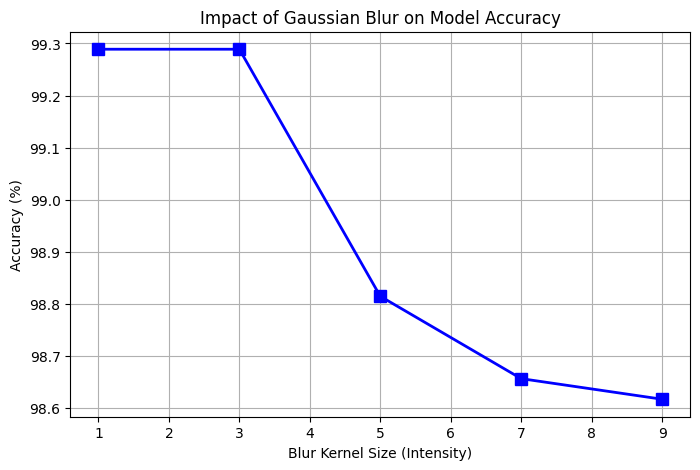

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import seaborn as sns
from sklearn.metrics import confusion_matrix
import torchvision.transforms as T


def visualize_results(dataloader, model, device, num_images=15):
    model.eval()


    images, labels = next(iter(dataloader))

    num_images = min(num_images, len(images))

    images_sub, labels_sub = images[:num_images].to(device), labels[:num_images].to(device)

    with torch.no_grad():
        outputs = model(images_sub)
        _, preds = torch.max(outputs, 1)


    rows = 3
    cols = 5
    plt.figure(figsize=(20, 12))

    for i in range(num_images):
        plt.subplot(rows, cols, i+1)


        img = images_sub[i].cpu().numpy().transpose((1, 2, 0))
        img = (img - img.min()) / (img.max() - img.min())

        plt.imshow(img)


        color = "green" if preds[i] == labels_sub[i] else "red"
        plt.title(f"Actual: {labels_sub[i].item()}\nPred: {preds[i].item()}", color=color, fontsize=10)
        plt.axis('off')

    plt.tight_layout()
    plt.show()


def plot_cm(model, dataloader, device):
    all_preds = []
    all_labels = []
    model.eval()
    print("Calculating Confusion Matrix...")
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()


def plot_robustness_graph(model, dataloader, device):
    blur_levels = [1, 3, 5, 7, 9]
    accuracies = []

    print("Generating Robustness Graph (this may take a moment)...")
    for b in blur_levels:
        blur_transform = T.GaussianBlur(kernel_size=b, sigma=(0.1, 2.0))
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in dataloader:
                images = blur_transform(images).to(device)
                labels = labels.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (preds == labels).sum().item()
        accuracies.append(100 * correct / total)

    plt.figure(figsize=(8, 5))
    plt.plot(blur_levels, accuracies, marker='s', color='b', linewidth=2, markersize=8)
    plt.title('Impact of Gaussian Blur on Model Accuracy')
    plt.xlabel('Blur Kernel Size (Intensity)')
    plt.ylabel('Accuracy (%)')
    plt.grid(True)
    plt.show()


visualize_results(val_loader, model, CONFIG['device'], num_images=15)
plot_cm(model, val_loader, CONFIG['device'])
plot_robustness_graph(model, val_loader, CONFIG['device'])